# Los 97 tiros publicados, los dieciséis casos y los artefactos versionados

**Nivel 1: Fundamentos** · Requiere: nada, este es el cuaderno de entrada · Tiempo de lectura: unos 15 minutos

## Objetivos

Fragmenta predice el tamaño medio de fragmento `x50` de una tronadura de banco, y mide cuánto vale cada predicción en una mina que el modelo no ha visto. Todo lo que muestra descansa en una tabla pequeña de mediciones reales. Este cuaderno abre esa tabla.

Al terminar habrá:

- cargado los 97 tiros publicados con el motor y leído los siete números que describen a cada uno;
- visto cómo los tiros se agrupan en diez campañas (sitios), que es la unidad que todos los cuadernos siguientes dejan fuera;
- listado los dieciséis casos sobre los que se construye el producto y abierto un artefacto versionado para ver qué escribió la ejecución offline.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Datos

Tres fuentes, todas leídas desde archivos, ninguna escrita a mano:

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| El corpus de entrenamiento de 97 tiros y los hold-outs | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo tiene derechos de autor y nunca se distribuye | la tabla dentro del paquete `blastfrag`, leída por `bf.load_training_corpus()` |
| El índice de casos | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/manifests/index.json` |
| Un artefacto de caso | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json` |

El corpus es adimensional: cada tiro se registra como razones (espaciamiento sobre bordo, altura de banco sobre bordo, bordo sobre diámetro de perforación, taco sobre bordo), un factor de carga, el tamaño de bloque in situ y el módulo de la roca, más el `x50` medido.

## Método

### Paso 1: importaciones y rutas

La celda siguiente importa el motor y fija la ruta a los artefactos versionados. El cuaderno se ejecuta desde su propia carpeta, así que la raíz del repositorio está tres niveles arriba; nunca se escribe una ruta absoluta.

In [2]:
# El motor, la numérica básica y la biblioteca de gráficos
import json
from collections import defaultdict
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

# Los artefactos versionados, relativos a la raíz del repositorio
DERIVED = Path("../../../data/derived")

### Paso 2: cargar el corpus

`load_training_corpus()` devuelve los 97 tiros como registros `Blast` inmutables. La carga también ejecuta la compuerta de integridad (el cuaderno 03 de este tema la abre): la llamada falla si una fila deja de reproducir los estadísticos descriptivos que imprime el artículo.

In [3]:
# Cargar los 97 tiros (la compuerta de integridad corre dentro de la llamada)
train = bf.load_training_corpus()
print("tiros:", len(train))
print("entradas, en el orden que usa cada ecuación publicada:", bf.FEATURES)
first = train[0]
print("primer tiro:", first.blast_id, first.site)
for name in bf.FEATURES:
    print(f"  {name:>9} = {getattr(first, name)}")
print(f"  {'x50_m':>9} = {first.x50_m}  (medido, metros)")

tiros: 97
entradas, en el orden que usa cada ecuación publicada: ('S_over_B', 'H_over_B', 'B_over_D', 'T_over_B', 'Pf_kg_m3', 'XB_m', 'E_GPa')
primer tiro: En1 Enusa
   S_over_B = 1.24
   H_over_B = 1.33
   B_over_D = 27.27
   T_over_B = 0.78
   Pf_kg_m3 = 0.48
       XB_m = 0.58
      E_GPa = 60.0
      x50_m = 0.37  (medido, metros)


### Paso 3: las diez campañas

Las filas de una misma campaña comparten macizo rocoso, equipo, suministro de explosivo y operador de medición, así que no son extracciones independientes. Este es el hecho estructural detrás de todo el producto, y la tabla lo vuelve concreto: una cantera aporta 22 de las 97 filas.

In [4]:
# Agrupar los tiros por sitio y resumir el tamaño medio medido de cada campaña
by_site = defaultdict(list)
for blast in train:
    by_site[blast.site].append(blast)

print(f"{'sitio':<14}{'n':>3}{'x50 medio (m)':>18}{'mín':>8}{'máx':>8}")
for site in sorted(by_site, key=lambda s: -len(by_site[s])):
    sizes = np.array([b.x50_m for b in by_site[site]])
    print(f"{site:<14}{len(sizes):>3}{sizes.mean():>18.3f}{sizes.min():>8.2f}{sizes.max():>8.2f}")

sitio           n     x50 medio (m)     mín     máx
Akdaglar       22             0.171    0.14    0.22
Enusa          12             0.396    0.26    0.64
Mrica          11             0.166    0.13    0.21
Reocin         10             0.616    0.44    0.96
Dongri-Buzurg   9             0.413    0.23    0.76
Murgul          7             0.311    0.23    0.38
Soma            7             0.224    0.15    0.28
Ozmert          7             0.191    0.12    0.30
Reocin-UG       6             0.593    0.51    0.69
Miami           6             0.080    0.02    0.10


La celda siguiente dibuja las mismas diez campañas como un gráfico de franjas del `x50` medido, un punto por tiro, para comparar las diferencias entre sitios con la dispersión dentro de cada sitio.

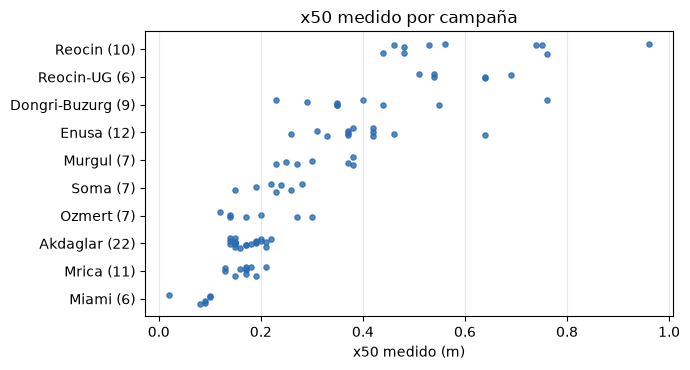

In [5]:
# Una fila de puntos por sitio, ordenada por el tamaño medio del sitio
order = sorted(by_site, key=lambda s: np.mean([b.x50_m for b in by_site[s]]))
fig, ax = plt.subplots(figsize=(7, 3.8))
rng = np.random.default_rng(0)
for row, site in enumerate(order):
    sizes = [b.x50_m for b in by_site[site]]
    ax.scatter(sizes, row + rng.uniform(-0.18, 0.18, len(sizes)), s=14, color="#2b6cb0", alpha=0.8)
ax.set_yticks(range(len(order)), [f"{s} ({len(by_site[s])})" for s in order])
ax.set_xlabel("x50 medido (m)")
ax.set_title("x50 medido por campaña")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

### Paso 4: el envolvente de las entradas

Un modelo ajustado con esta tabla solo es confiable dentro de los rangos que la tabla cubre. `envelope_report` indica el rango de cada entrada en las 97 filas y lo contrasta con el envolvente que declara el motor (`TRAINING_ENVELOPE`).

In [6]:
# El rango de cada entrada en el corpus, y cuántas filas quedan fuera del envolvente declarado
report = bf.envelope_report(train)
print(f"{'entrada':<10}{'mín':>8}{'máx':>8}{'media':>8}{'fuera':>9}")
for name, stat in report.items():
    print(f"{name:<10}{stat['min']:>8.2f}{stat['max']:>8.2f}{stat['mean']:>8.2f}{stat['n_outside_envelope']:>9}")

entrada        mín     máx   media    fuera
S_over_B      1.00    1.75    1.19        0
H_over_B      1.33    6.82    3.35        0
B_over_D     17.98   39.47   27.35        0
T_over_B      0.50    4.67    1.26        0
Pf_kg_m3      0.22    1.26    0.53        0
XB_m          0.02    2.35    1.11        0
E_GPa         9.57   60.00   29.46        0


### Paso 5: los tres conjuntos de validación

Además del corpus de entrenamiento el motor incluye dos conjuntos de validación publicados (2010 y 2012, que se traslapan) y cinco tiros de campo de acceso abierto de una mina de granito cuyo módulo queda bajo el mínimo de entrenamiento, por lo que se marcan como extrapolación.

In [7]:
# Los hold-outs publicados y el conjunto de campo, con el rango de módulo de cada uno
sets = {"2010": bf.load_holdout(protocol="2010"), "2012": bf.load_holdout(protocol="2012"),
        "campo": bf.load_field_holdout()}
for name, blasts in sets.items():
    modulus = [b.E_GPa for b in blasts]
    print(f"{name:>8}: {len(blasts):>2} tiros, E = {min(modulus):.2f} a {max(modulus):.2f} GPa")
print("E mínimo de entrenamiento:", min(b.E_GPa for b in train), "GPa")

    2010: 13 tiros, E = 9.57 a 60.00 GPa
    2012: 12 tiros, E = 9.57 a 60.00 GPa
   campo:  5 tiros, E = 5.60 a 5.60 GPa
E mínimo de entrenamiento: 9.57 GPa


### Paso 6: los dieciséis casos

Un caso es un conjunto coherente de tiros que responde una pregunta: diez campañas reales, un conjunto de campo real fuera del envolvente y cinco diseños sintéticos (dos de ellos controles). La ejecución offline escribió un índice de todos; la celda lo lee y cuenta los casos por categoría.

In [8]:
# Leer el índice versionado y contar los casos por categoría
index = json.loads((DERIVED / "manifests" / "index.json").read_text(encoding="utf-8"))
counts = defaultdict(list)
for case in index["cases"]:
    counts[case["category"]].append(case["case_id"])
print("casos:", index["n_cases"], "| schema:", index["schema"], "| generado por la app", index["app_version"])
for category, ids in counts.items():
    print(f"  {category:<24}{len(ids):>2}  {', '.join(ids)}")

casos: 16 | schema: fragmenta.index/v1 | generado por la app 0.08.001
  negative-control         2  ctrl-degenerate, real-miami
  positive-control         1  ctrl-oracle
  real-campaign            9  real-akdaglar, real-dongri-buzurg, real-enusa, real-mrica, real-murgul, real-ozmert, real-reocin, real-reocin-ug, real-soma
  extrapolation-control    1  real-granite-ne
  structural-control       1  synth-ibsd-capped
  parameter-sweep          2  synth-sweep-burden, synth-sweep-powder


### Paso 7: abrir un artefacto

Cada caso tiene un artefacto, `case.json`, que guarda los tiros, la predicción de cada brazo (un número o una negativa explícita), los puntajes y la procedencia. El sitio nunca recalcula estos documentos; los reproduce. La celda abre el caso Enusa y comprueba que el artefacto se generó con el mismo corpus que trae el motor instalado, comparando resúmenes criptográficos.

In [9]:
# Abrir el artefacto de Enusa y comparar su resumen del corpus con el calculado desde el motor instalado
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
print("secciones del artefacto:", sorted(artifact))
print("tiros en el caso:", len(artifact["blasts"]))
print("brazos con predicción:", len(artifact["predictions"]))
print("motor que lo generó:", artifact["provenance"]["engine"]["version"])
digest = bf.datasets.compute_dataset_digest(train)
print("mismo corpus que el motor instalado:", artifact["provenance"]["corpus_digest"] == digest)

secciones del artefacto: ['blasts', 'case', 'controls', 'digest', 'distributions', 'geometry_report', 'live_models', 'null_mean_m', 'predictions', 'provenance', 'representative_blast_id', 'schema', 'scores', 'variant_curves', 'variants']
tiros en el caso: 12
brazos con predicción: 14
motor que lo generó: 0.04.000
mismo corpus que el motor instalado: True


## Resultados

**Qué muestran los números.** El corpus tiene 97 tiros de diez campañas en cinco países. Las campañas son muy desiguales: una cantera aporta 22 filas y dos campañas aportan solo seis, y los tamaños medios medidos difieren entre campañas más que la dispersión dentro de la mayoría de ellas (el gráfico de franjas). Por eso este producto deja fuera campañas completas y no tiros sueltos.

**Qué dice el envolvente.** Las 97 filas están dentro del envolvente declarado y el módulo de la roca va de cerca de 10 a 60 GPa. Los cinco tiros de campo tienen un módulo de 5,6 GPa, bajo ese mínimo, así que toda predicción allí es una extrapolación y se marca como tal.

**Qué dicen los casos y el artefacto.** Los dieciséis casos son las preguntas que responde el producto; el artefacto de uno de ellos guarda la respuesta de cada brazo, y su resumen del corpus coincide con el calculado desde el motor instalado, de modo que la evidencia versionada y el motor describen los mismos 97 tiros.

**Qué no muestra esto.** Aquí aún no se predice ni se puntúa nada: el cuaderno solo abre los datos. Tampoco dice si los números son correctos respecto del artículo; eso lo hace la compuerta de integridad del cuaderno 03 de este tema.

## Resumen

- El motor carga los 97 tiros publicados en una llamada y los contrasta con el artículo mientras los carga.
- Los tiros vienen de diez campañas, y la campaña, no el tiro, es la unidad que lleva la dependencia.
- Hay dieciséis casos indexados, y cada uno tiene un artefacto versionado cuyo resumen del corpus lo une al corpus del motor.
- Siguiente: el cuaderno 02 reconstruye la geometría absoluta a partir de las razones, que es lo que necesita la ecuación clásica.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus de 97 tiros y el primer hold-out)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/